# 08 — Consensus clustering of the Track-1 topic phrases

**Purpose.** Induce the codebook's candidate clusters from the **Track-1
(hearing-level) phrases only** — the layered architecture ratified by the
researcher on 2026-08-22: Track 1 defines the hearing-level topic map;
Track-2 stance records are later *assigned into* that map (notebook 10),
keeping their finer utterance-level phrasing as within-topic detail rather
than flattening it into the clustering.

**Two design decisions carried from the superseded pooled run, with the
evidence that motivated them:**

1. **Track-1-only input.** In the pooled run only 4.6% of unique phrases
   appeared in both tracks — the tracks speak different granularity layers
   (hearing subjects vs. position objects), and mixing them blurs the
   taxonomy's level of analysis.
2. **Stability is a reported diagnostic, not an inclusion gate.** A
   decomposition on 1,236 CAP-matched hearings showed the full K=120
   consensus cut matched the v0 baseline on human-coding agreement
   (top-1 25.0% vs 24.7%, NMI 0.551 vs 0.553), while gating at mean
   co-assignment ≥ 0.5 destroyed it (20.4% / 0.475): the gate discarded
   unstable-but-valid granularity. Ratification itself cost nothing.
   Per-cluster stability is therefore reported in the codebook and the
   paper, and gates nothing.

**Method** (as validated in the pooled run): normalization for clustering
only (years, bill numbers, trailing Act/reauthorization); average-linkage
micro-families at cosine 0.90 (immune to single-link chaining); per-K
Monti consensus (B=30 weight-proportional 80% subsamples per candidate K);
criteria curves for the researcher-approved operating point.

**Inputs.** `track1/topics.parquet` (04).

**Outputs** (`interim/topics/taxonomy/`): `phrases.parquet`,
`families.parquet`, embeddings, `cut_labels.parquet`,
`cluster_stats.parquet`, `criteria_curves.csv`;
`paper/figures/fig_taxonomy_criteria.pdf/.svg`.

## Step 1 — Track-1 phrase table

In [1]:
import json as _json
import re
import sys

sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd

from paths import HF_CACHE, topics_run_dir

import os
os.environ["HF_HOME"] = str(HF_CACHE)

SEED = 1089
rng = np.random.default_rng(SEED)
TAX = topics_run_dir("taxonomy")

t1_raw = pd.read_parquet(topics_run_dir("track1") / "topics.parquet",
                         columns=["topics_json"])
pool = pd.DataFrame({"phrase": [t["topic"] for js in t1_raw["topics_json"]
                                for t in _json.loads(js)]})
pool["key"] = pool["phrase"].str.casefold().str.strip()
units = (pool.groupby("key")
             .agg(phrase=("phrase", lambda s: s.value_counts().index[0]),
                  weight=("phrase", "size")).reset_index())
print(f"Track-1 mentions: {len(pool):,} -> unique phrases: {len(units):,}")

Track-1 mentions: 11,592 -> unique phrases: 9,095


## Step 2 — Normalization for the clustering input

Same rules as validated before: years and bill numbers removed, trailing
"Act"/"reauthorization" stripped when a substantive stem remains; phrases
that normalize to nothing go to the explicit other pool.

In [2]:
BILL = re.compile(r"\b(?:h\.?\s?r\.?|s\.?)\s?\d+\b", re.IGNORECASE)
YEAR = re.compile(r"\b(?:19|20)\d{2}\b")
TRAIL = re.compile(r"\s+(?:reauthorization|reauthorizations|act)\s*$",
                   re.IGNORECASE)

def norm_for_clustering(phrase):
    s = BILL.sub(" ", phrase)
    s = YEAR.sub(" ", s)
    s = re.sub(r"\bof\s*$", " ", TRAIL.sub(" ", s))
    s = TRAIL.sub(" ", s)
    return re.sub(r"[\s\-–—,.()]+$", "", re.sub(r"\s+", " ", s)).strip()

units["norm"] = units["phrase"].map(norm_for_clustering)
units["clusterable"] = units["norm"].str.len() >= 3
norm_units = (units[units["clusterable"]]
              .groupby(units["norm"].str.casefold())
              .agg(norm=("norm", "first"), weight=("weight", "sum"))
              .reset_index(names="norm_key"))
print(f"unclusterable -> other: {(~units['clusterable']).sum():,}; "
      f"clustering units: {len(norm_units):,}")

unclusterable -> other: 79; clustering units: 8,736


## Step 3 — Embeddings (pinned encoder, GPU)

In [3]:
import torch
from transformers import AutoModel, AutoTokenizer

import relevance as R

EMB = TAX / "unit_embeddings.npz"
if EMB.exists():
    dat = np.load(EMB, allow_pickle=True)
    assert list(dat["norm_key"]) == list(norm_units["norm_key"])
    X = dat["X"].astype(np.float32)
    print("reused cached embeddings")
else:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(R.ENCODER)
    enc = AutoModel.from_pretrained(R.ENCODER, dtype="auto",
                                    device_map=dev).eval()
    with torch.no_grad():
        X = R.encode(norm_units["norm"].tolist(), enc, tok,
                     R.ENCODER).astype(np.float32)
    np.savez_compressed(EMB, X=X.astype(np.float16),
                        norm_key=np.array(norm_units["norm_key"]))
    del enc
    torch.cuda.empty_cache()
print(f"X {X.shape}")

reused cached embeddings
X (8736, 1024)


## Step 4 — Micro-families (average linkage, cosine ≥ 0.90)

Average linkage, not connected components: single-link chaining produced a
4,736-unit hairball in the pooled run and is documented there as the
failure mode this choice avoids.

In [4]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

FAMILY_COS = 0.90
FAM_CACHE = TAX / "family_assignment.npz"
if FAM_CACHE.exists():
    _fc = np.load(FAM_CACHE)
    assert len(_fc["fam"]) == len(norm_units)
    fam = _fc["fam"]
    print("reused cached family assignment")
else:
    Xg = torch.tensor(X, device="cuda" if torch.cuda.is_available()
                      else "cpu")
    Du = np.empty((len(X), len(X)), dtype=np.float32)
    for i in range(0, len(X), 4096):
        Du[i:i + 4096] = (1.0 - (Xg[i:i + 4096] @ Xg.T)).clamp(
            min=0).cpu().numpy()
    del Xg
    torch.cuda.empty_cache()
    np.fill_diagonal(Du, 0.0)
    Zu = linkage(squareform(Du, checks=False), method="average")
    del Du
    fam = fcluster(Zu, t=1.0 - FAMILY_COS, criterion="distance") - 1
    np.savez_compressed(FAM_CACHE, fam=fam, threshold=FAMILY_COS)
n_fam = fam.max() + 1
norm_units["family_id"] = fam

w = norm_units["weight"].to_numpy(dtype=np.float64)
F = np.zeros((n_fam, X.shape[1]), dtype=np.float64)
np.add.at(F, fam, X * w[:, None])
F /= np.linalg.norm(F, axis=1, keepdims=True)
F = F.astype(np.float32)
fam_w = np.bincount(fam, weights=w)
sizes = np.bincount(fam)
print(f"{n_fam:,} families (max size {sizes.max()}, "
      f"singletons {(sizes == 1).sum():,})")
assert sizes.max() < 500

reused cached family assignment
7,712 families (max size 15, singletons 6,937)


## Step 5 — Per-K Monti consensus and criteria (stability reported, not gating)

In [5]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

B = 30
GRID = [15, 20, 25, 40, 60, 80, 100, 120, 150]
DONE = all((TAX / f).exists() for f in
           ("criteria_curves.csv", "cut_labels.parquet",
            "cluster_stats.parquet"))
if DONE:
    curves = pd.read_csv(TAX / "criteria_curves.csv")
    DONE = list(curves["K"]) == GRID
    if DONE:
        print("reused cached per-K consensus results")
        print(curves.to_string(index=False))
if not DONE:
    p = fam_w / fam_w.sum()
    sil_idx = rng.choice(n_fam, size=min(4000, n_fam), replace=False, p=p)
    curves, cut_labels, cluster_stats = [], {}, []
    for K in GRID:
        co = np.zeros((n_fam, n_fam), dtype=np.uint8)
        for b in range(B):
            sub = rng.choice(n_fam, size=int(0.8 * n_fam), replace=False,
                             p=p)
            km = MiniBatchKMeans(n_clusters=K, n_init=3, batch_size=4096,
                                 random_state=int(rng.integers(2**31)))
            km.fit(F[sub], sample_weight=fam_w[sub])
            labels = km.predict(F)
            for k in range(K):
                idx = np.flatnonzero(labels == k)
                co[np.ix_(idx, idx)] += 1
        D = 1.0 - co.astype(np.float32) / B
        np.fill_diagonal(D, 0.0)
        lab = fcluster(linkage(squareform(D, checks=False),
                               method="average"), t=K, criterion="maxclust")
        del D
        cut_labels[K] = lab
        stab = np.zeros(K); coh = np.zeros(K); wsum = np.zeros(K)
        for k in range(1, K + 1):
            idx = np.flatnonzero(lab == k)
            wsum[k - 1] = fam_w[idx].sum()
            stab[k - 1] = (co[np.ix_(idx, idx)].mean() / B
                           if len(idx) > 1 else 1.0)
            coh[k - 1] = float(np.linalg.norm(F[idx].mean(0)) ** 2)
            cluster_stats.append({"K": K, "cluster": k,
                                  "weight": wsum[k - 1],
                                  "n_fam": len(idx),
                                  "stability": stab[k - 1],
                                  "cohesion": coh[k - 1]})
        del co
        curves.append({
            "K": K,
            "stability_w": (stab * wsum).sum() / wsum.sum(),
            "silhouette": silhouette_score(F[sil_idx], lab[sil_idx],
                                           metric="cosine"),
            "cohesion_flags": int((coh < 0.55).sum()),
            "share_stab50": wsum[stab >= 0.5].sum() / fam_w.sum(),
        })
        print(f"  K={K:>3}: stability {curves[-1]['stability_w']:.2f}, "
              f"silhouette {curves[-1]['silhouette']:.3f}, "
              f"cohesion flags {curves[-1]['cohesion_flags']}")
    curves = pd.DataFrame(curves)
    pd.DataFrame({f"K{K}": v for K, v in cut_labels.items()}).assign(
        family_id=np.arange(n_fam)).to_parquet(TAX / "cut_labels.parquet",
                                               index=False)
    pd.DataFrame(cluster_stats).to_parquet(TAX / "cluster_stats.parquet",
                                           index=False)
    curves.to_csv(TAX / "criteria_curves.csv", index=False)
    print(curves.to_string(index=False))

  K= 15: stability 0.52, silhouette 0.047, cohesion flags 5


  K= 20: stability 0.48, silhouette 0.042, cohesion flags 2


  K= 25: stability 0.47, silhouette 0.008, cohesion flags 5


  K= 40: stability 0.46, silhouette 0.027, cohesion flags 5


  K= 60: stability 0.44, silhouette 0.015, cohesion flags 4


  K= 80: stability 0.46, silhouette 0.037, cohesion flags 4


  K=100: stability 0.47, silhouette 0.024, cohesion flags 4


  K=120: stability 0.46, silhouette 0.027, cohesion flags 6


  K=150: stability 0.47, silhouette 0.036, cohesion flags 3
  K  stability_w  silhouette  cohesion_flags  share_stab50
 15     0.524940    0.047182               5      0.430545
 20     0.483788    0.042386               2      0.350447
 25     0.471012    0.007551               5      0.353227
 40     0.463762    0.026935               5      0.378594
 60     0.443439    0.014966               4      0.289375
 80     0.459725    0.036738               4      0.357137
100     0.465815    0.023837               4      0.319520
120     0.463900    0.027363               6      0.351316
150     0.474066    0.035660               3      0.389975


## Step 6 — Persist phrase → unit → family mapping

In [6]:
cl = units[units["clusterable"]].copy()
nk = {n: i for i, n in enumerate(norm_units["norm_key"])}
cl["unit_id"] = cl["norm"].str.casefold().map(nk)
cl["family_id"] = norm_units["family_id"].to_numpy()[cl["unit_id"]]
other = units[~units["clusterable"]].assign(unit_id=-1, family_id=-1)
phrases = pd.concat([cl, other], ignore_index=True)
phrases.to_parquet(TAX / "phrases.parquet", index=False)
fam_tbl = (cl.groupby("family_id")
           .agg(representative=("phrase", lambda s: s.iloc[
               np.argmax(cl.loc[s.index, "weight"].values)]),
                weight=("weight", "sum"), n_phrases=("phrase", "size"))
           .reset_index())
fam_tbl.to_parquet(TAX / "families.parquet", index=False)
print(f"phrases {len(phrases):,} | families {len(fam_tbl):,}")

phrases 9,095 | families 7,712


## Criteria-curve figure (house layout rules)

No coverage-at-gate line this time — stability is a diagnostic, so the
curves show weighted stability, silhouette, and cohesion flags; the share
above the old 0.5 bar is kept as a reference series only.

saved fig_taxonomy_criteria.pdf/.svg


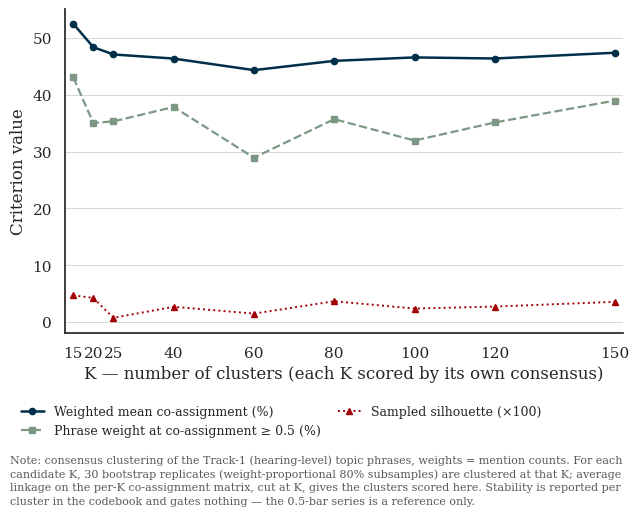

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

from paths import FIGURES

NAVY, RED, GREEN = "#003049", "#A30006", "#7C9885"
GRID_C = "#D0D0D0"
sns.set_theme(style="white", font="serif",
              rc={"font.serif": ["DejaVu Serif", "Times New Roman",
                                 "serif"]})
CM_IN = 1 / 2.54

def wrap_to_px(fig, ren, text, width_px, fontsize=8):
    probe = fig.text(0, 0, "", fontsize=fontsize)
    out, cur = [], ""
    for word in text.split():
        trial = f"{cur} {word}".strip()
        probe.set_text(trial)
        if probe.get_window_extent(ren).width <= width_px or not cur:
            cur = trial
        else:
            out.append(cur); cur = word
    out.append(cur); probe.remove()
    return "\n".join(out)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(curves["K"], curves["stability_w"] * 100, "-o", color=NAVY,
        ms=4.5, lw=1.8, label="Weighted mean co-assignment (%)")
ax.plot(curves["K"], curves["share_stab50"] * 100, "--s", color=GREEN,
        ms=4, lw=1.6, label="Phrase weight at co-assignment ≥ 0.5 (%)")
ax.plot(curves["K"], curves["silhouette"] * 100, ":^", color=RED,
        ms=4, lw=1.4, label="Sampled silhouette (×100)")
ax.set_xticks(curves["K"])
ax.set_xlabel("K — number of clusters (each K scored by its own consensus)")
ax.set_ylabel("Criterion value")
ax.set_xlim(curves["K"].min() - 2, curves["K"].max() + 2)
ax.yaxis.grid(True, color=GRID_C, linewidth=0.6)
ax.xaxis.grid(False)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.canvas.draw()
ren = fig.canvas.get_renderer()
dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
gap = 0.3 * CM_IN * dpi
x0px = ax.yaxis.label.get_window_extent(ren).x0
x1px = ax.get_window_extent(ren).x1
xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
handles, labels = ax.get_legend_handles_labels()
leg = fig.legend(handles, labels, frameon=False, loc="upper left",
                 bbox_to_anchor=(x0px / W, (xlab_bot - gap) / H),
                 bbox_transform=fig.transFigure, ncol=2, fontsize=9,
                 handlelength=1.8, columnspacing=1.4)
fig.canvas.draw()
note = ("Note: consensus clustering of the Track-1 (hearing-level) topic "
        "phrases, weights = mention counts. For each candidate K, 30 "
        "bootstrap replicates (weight-proportional 80% subsamples) are "
        "clustered at that K; average linkage on the per-K co-assignment "
        "matrix, cut at K, gives the clusters scored here. Stability is "
        "reported per cluster in the codebook and gates nothing — the "
        "0.5-bar series is a reference only.")
fig.text(x0px / W, (leg.get_window_extent(ren).y0 - gap) / H,
         wrap_to_px(fig, ren, note, x1px - x0px), ha="left", va="top",
         fontsize=8, color="0.35", linespacing=1.4)
for ext in ("pdf", "svg"):
    fig.savefig(FIGURES / f"fig_taxonomy_criteria.{ext}",
                bbox_inches="tight")
print("saved fig_taxonomy_criteria.pdf/.svg")

## Verification

In [8]:
back = pd.read_parquet(TAX / "phrases.parquet")
assert back["weight"].sum() == units["weight"].sum()
print(f"1) Track-1 phrases : {len(units):,} unique / "
      f"{units['weight'].sum():,} mentions")
print(f"2) families        : {n_fam:,} (avg linkage, max {sizes.max()})")
print(f"3) consensus       : per-K Monti, B={B}, grid {GRID}")
print(f"4) stability role  : reported diagnostic, no gate")
print(f"5) NEXT            : operating point + codebook draft (09)")

1) Track-1 phrases : 9,095 unique / 11,592 mentions
2) families        : 7,712 (avg linkage, max 15)
3) consensus       : per-K Monti, B=30, grid [15, 20, 25, 40, 60, 80, 100, 120, 150]
4) stability role  : reported diagnostic, no gate
5) NEXT            : operating point + codebook draft (09)
